# Demo - Author's Pretrained DSA-RNN

Runs the **original author's model** (`demo_model`) on their test features and reproduces the
paper's demo output: the per-frame **accident probability** and the **spatial attention** over
objects.

The original `accident.py` is TensorFlow 1.x / Python 2 and cannot run unchanged on TF 2. To
run the author's model *without modifying it*, we load the graph they saved (`import_meta_graph`)
and restore the trained weights - this is their exact network and parameters, run through
`tensorflow.compat.v1`.

(The original `--mode demo` video overlay needs `det`/`ID` arrays the released `.npz` lack, so
we show the probability curve and the attention heatmap instead.)

Needs locally: `author_code/demo_model/` and `Dataset/features/test/`.

## 1. Load the author's trained model

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()

META = '../author_code/demo_model/demo_model.meta'
CKPT = '../author_code/demo_model/demo_model'

tf.reset_default_graph()
saver = tf.train.import_meta_graph(META)
sess  = tf.Session()
saver.restore(sess, CKPT)
print('model restored.')

g         = tf.get_default_graph()
x         = g.get_tensor_by_name('Placeholder:0')      # (10,100,20,4096)
y         = g.get_tensor_by_name('Placeholder_1:0')    # (10,2)
keep      = g.get_tensor_by_name('Placeholder_2:0')    # dropout keep
soft_pred = g.get_tensor_by_name('model_99/concat_4:0')  # (10,100) P(accident) per frame
all_alphas= g.get_tensor_by_name('model_99/concat_5:0')  # (100,19,10) attention weights

Instructions for updating:
non-resource variables are not supported in the long term
INFO:tensorflow:Restoring parameters from ../author_code/demo_model/demo_model
model restored.


## 2. Run the model on one test batch
`keep=[0.0]` means no dropout (inference). Pick which batch to view.

In [5]:
BATCH = 2
d = np.load(f'../Dataset/features/test/batch_{BATCH:03d}.npz')
data   = d['data'].astype(np.float32)
labels = d['labels'].astype(np.float32)

pred, alphas = sess.run([soft_pred, all_alphas],
                        feed_dict={x: data, y: labels, keep: [0.0]})
print('pred:', pred.shape, ' alphas:', alphas.shape)
print('labels:', ['A' if r[1]==1 else 'n' for r in labels])

pred: (10, 100)  alphas: (100, 19, 10)
labels: ['n', 'n', 'n', 'n', 'A', 'n', 'A', 'A', 'A', 'n']


## 3. Demo output - accident probability per frame
For accident clips the probability should rise toward the crash (frame 90). The vertical line
marks the moment of accident.

In [ ]:
plt.figure(figsize=(11, 5))
seen = set()
for i in range(10):
    is_acc = labels[i, 1] == 1
    cls = 'accident' if is_acc else 'no-accident'
    lbl = cls if cls not in seen else None   # label only the first of each class
    seen.add(cls)
    plt.plot(pred[i, 0:90],
             lw=2.5 if is_acc else 1.0,
             color='crimson' if is_acc else 'steelblue',
             alpha=0.9 if is_acc else 0.5,
             label=lbl)
plt.axvline(90, ls='--', c='gray')
plt.ylim(0, 1); plt.xlabel('frame'); plt.ylabel('P(accident)')
plt.title(f'Accident probability per frame (test batch {BATCH})')
plt.legend()
plt.show()

## 4. Demo output - spatial attention for one accident clip
The model's attention over the (up to) 19 object slots, frame by frame. Brighter = the model is
"looking at" that object more. This is the Dynamic-Spatial-Attention at work.

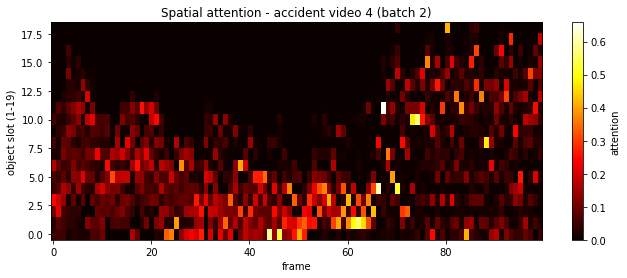

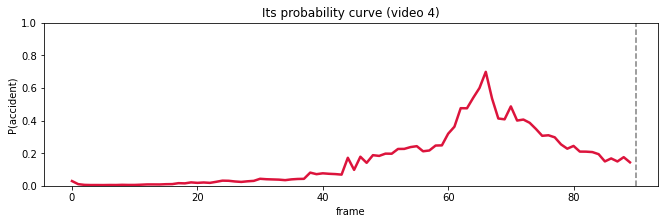

In [7]:
# first accident video in this batch
acc_idx = next((i for i in range(10) if labels[i, 1] == 1), 0)
att = alphas[:, :, acc_idx]          # (100 frames, 19 objects)

plt.figure(figsize=(11, 4))
plt.imshow(att.T, aspect='auto', origin='lower', cmap='hot')
plt.colorbar(label='attention')
plt.xlabel('frame'); plt.ylabel('object slot (1-19)')
plt.title(f'Spatial attention - accident video {acc_idx} (batch {BATCH})')
plt.show()

plt.figure(figsize=(11, 3))
plt.plot(pred[acc_idx, 0:90], color='crimson', lw=2.5)
plt.axvline(90, ls='--', c='gray'); plt.ylim(0, 1)
plt.xlabel('frame'); plt.ylabel('P(accident)')
plt.title(f'Its probability curve (video {acc_idx})')
plt.show()

## Notes
- This is the author's **unmodified** trained model (their saved graph + weights), run on TF 2
  via `compat.v1`. No model code was rewritten.
- Change `BATCH` to view other test batches; `Dataset/features/test/` must hold the real
  (distinct) author features.
- For the overall numbers (Average Precision, Time-to-Accident) across all 46 test batches, see
  `10_run_author_demo.ipynb`.